In [18]:
import rebound as rb
import pandas as pd

In [12]:
luthys = [ rb.Simulation(f'./luthera_sims/luther_sim_{sim_no:04}.bin') for sim_no in range(6)]


In [4]:
len(luthys[0].particles)

19

In [8]:
print(luthys[0].particles[0].x)


-0.002460857541440711


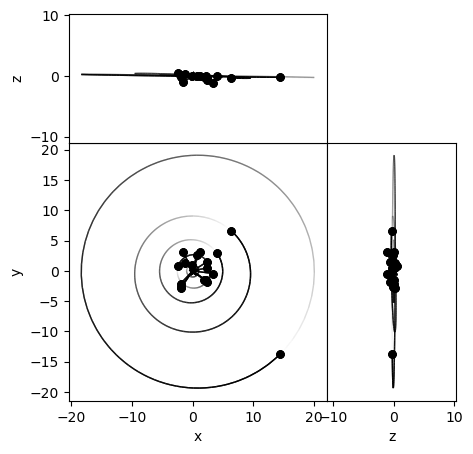

In [9]:
rb.OrbitPlotSet(luthys[0])

In [11]:
luthy_fins = [ rb.Simulation(f'./luthera_sims/luther_sim_{sim_no:04}_fin.bin') for sim_no in range(6)]


ValueError: Unbound orbit can't have f beyond the range allowed by the asymptotes set by the hyperbola.

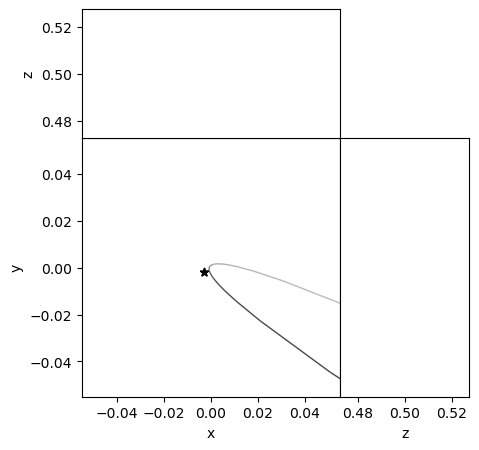

In [14]:
rb.OrbitPlotSet(luthy_fins[0])

In [16]:
sim = rb.Simulation()
date = 'JD2451544.5'
# Abbrev 'Venus', 'Neptune'
sim.add(['Sun', 'Earth', 'Ceres', 'Jupiter', 'Saturn', 'Uranus'], date=date)
sim.integrator = "whfast"
sim.particles[3].m = 5.21e-10  # Ceres Mass in Solar masses
sim.dt = sim.particles[1].P / 30  # 1/30 of the innermost planetary period
sim.N_active = 6
sim.testparticle_type = 1
sim.move_to_com()


    

Searching NASA Horizons for 'Sun'... 
Found: Sun (10) 
Searching NASA Horizons for 'Earth'... 
Found: Earth-Moon Barycenter (3) (chosen from query 'Earth')
Searching NASA Horizons for 'Ceres'... 
Found: 1 Ceres (A801 AA) 
Searching NASA Horizons for 'Jupiter'... 


/Users/brettwalker/opt/anaconda3/envs/rebound/lib/python3.11/site-packages/rebound/horizons.py:168: RuntimeWarning: Warning: Mass cannot be retrieved from NASA HORIZONS. Set to 0.
  warnings.warn("Warning: Mass cannot be retrieved from NASA HORIZONS. Set to 0.", RuntimeWarning)


Found: Jupiter Barycenter (5) (chosen from query 'Jupiter')
Searching NASA Horizons for 'Saturn'... 
Found: Saturn Barycenter (6) (chosen from query 'Saturn')
Searching NASA Horizons for 'Uranus'... 
Found: Uranus Barycenter (7) (chosen from query 'Uranus')


In [20]:
lth_eph_df = pd.read_pickle('luthera_eph.pkl')


# produce a new column for each of the clones as values +- sigma
lth_eph_df['Xcp'] = lth_eph_df['X'] * (1 + lth_eph_df['sX'])
lth_eph_df['Ycp'] = lth_eph_df['Y'] * (1 + lth_eph_df['sY'])
lth_eph_df['Zcp'] = lth_eph_df['Z'] * (1 + lth_eph_df['sZ'])
lth_eph_df['Xcm'] = lth_eph_df['X'] * (1 - lth_eph_df['sX'])
lth_eph_df['Ycm'] = lth_eph_df['Y'] * (1 - lth_eph_df['sY'])
lth_eph_df['Zcm'] = lth_eph_df['Z'] * (1 - lth_eph_df['sZ'])
lth_eph_df['VXcp'] = lth_eph_df['VX'] * (1 + lth_eph_df['sVX'])
lth_eph_df['VYcp'] = lth_eph_df['VY'] * (1 + lth_eph_df['sVY'])
lth_eph_df['VZcp'] = lth_eph_df['VZ'] * (1 + lth_eph_df['sVZ'])
lth_eph_df['VXcm'] = lth_eph_df['VX'] * (1 - lth_eph_df['sVX'])
lth_eph_df['VYcm'] = lth_eph_df['VY'] * (1 - lth_eph_df['sVY'])
lth_eph_df['VZcm'] = lth_eph_df['VZ'] * (1 - lth_eph_df['sVZ'])


In [26]:
lth_eph_df[['X','Xcp','Xcm']].head()

,X,Xcp,Xcm
0,3.359408,3.359409,3.359408
1,2.140391,2.140392,2.140390
2,0.840324,0.840324,0.840324
3,2.750743,2.750744,2.750743
4,-2.853475,-2.853476,-2.853474


In [ ]:
run_length = 1.0e6

n_particles = len(sim.particles) - sim.N_active

# Create evenly spaced integrations every run_length/1000
log_time = int(run_length/1.0e3)
vals: int = 9
# Integrate for run_length years
times = np.linspace(log_time, run_length * 2 * np.pi, log_time)
start = time.time()

run_values = np.zeros((log_time, n_particles, vals))
# Capture warning messages (WHFast timestep too large)
print(f'+{sim_no} {run_length}')
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    for ti, t in enumerate(times):
        sim.integrate(t, exact_finish_time=0)
        for i, p in enumerate(sim.particles[sim.N_active:]):
            run_values[ti][i][0] = p.x
            run_values[ti][i][1] = p.y
            run_values[ti][i][2] = p.z
            run_values[ti][i][3] = p.vx
            run_values[ti][i][4] = p.vy
            run_values[ti][i][5] = p.vz
            run_values[ti][i][6] = p.a
            run_values[ti][i][7] = p.e
            run_values[ti][i][8] = p.inc

print(f'-{sim_no} {run_length}: {time.time()-start}')
